# Caribou Migration

The following project is an investigation into the migration of the *Rangifer tarandus granti*, also known as the largest herd of Caribou that exists in North America. Human observation data of the herd was downloaded from gbif.org.

In [21]:
### load libraries

### GBIF packages
import pygbif.occurrences as occ ### get GBIF occurrence data
import pygbif.species as species ### deals with species names

### time processing
import time 

### read and extract .zip folders
import zipfile 

### handles sensitive inputs like passwords and API tokens
from getpass import getpass 

### function for finding file paths
from glob import glob 

### make requests to websites and web APIs
import requests 

### folder/file management
import os
import pathlib

### tabular data
import pandas as pd
from shapely.geometry import Point, Polygon, LineString


### handle geospatial vector data
import geopandas as gpd

### access prepped gbif data
import earthpy as et

### manage coordinate reference systems
import cartopy.crs as ccrs

### customize the dynamic plot
import panel as pn

### make dynamic plot with geodataframe
import hvplot.pandas
import holoviews as hv

### get month names
import calendar


## Download data

In [35]:
### change this to reset = False after you run this chunk the first time
reset = True

####--------------------------------------####
#### DO NOT MODIFY THE REST OF THIS CODE! ####
####--------------------------------------####
### This code asks for your credentials and saves it for the rest of the session.
### NEVER put your credentials into your code!!!!
### GBIF needs a username, password, and email 

### request and store username
if (not ('GBIF_USER'  in os.environ)) or reset:
    os.environ['GBIF_USER'] = input('GBIF username:')

### securely request and store password
if (not ('GBIF_PWD'  in os.environ)) or reset:
    os.environ['GBIF_PWD'] = getpass('GBIF password:')
    
### request and store account email address
if (not ('GBIF_EMAIL'  in os.environ)) or reset:
    os.environ['GBIF_EMAIL'] = input('GBIF email:')

In [27]:
### create data directory
data_dir = os.path.join(

    ### point to your home directory
    pathlib.Path.home(),

    ### nest the data in the folder where your assignments live
    'earth-analytics',
    'data',
    
    ### make a project directory for this assignment
    'caribou_migration_new'
    )

### make the directory
os.makedirs(data_dir, exist_ok = True)

### define directory for the gbif data
gbif_dir = os.path.join(data_dir, 'gbif')

### make the directory
os.makedirs(gbif_dir, exist_ok = True)

In [28]:
### define the species name you will be using
backbone = species.name_backbone(scientificName = 'Rangifer tarandus granti')

### check it out
backbone


{'usage': {'key': '5220119',
  'name': 'Rangifer tarandus granti J.A.Allen, 1902',
  'canonicalName': 'Rangifer tarandus granti',
  'authorship': 'J.A.Allen, 1902',
  'rank': 'SUBSPECIES',
  'code': 'ZOOLOGICAL',
  'status': 'SYNONYM',
  'genericName': 'Rangifer',
  'specificEpithet': 'tarandus',
  'infraspecificEpithet': 'granti',
  'type': 'SCIENTIFIC',
  'formattedName': '<i>Rangifer</i> <i>tarandus</i> <i>granti</i> J.A.Allen, 1902'},
 'acceptedUsage': {'key': '5220116',
  'name': 'Rangifer tarandus groenlandicus (Borowski, 1780)',
  'canonicalName': 'Rangifer tarandus groenlandicus',
  'authorship': '(Borowski, 1780)',
  'rank': 'SUBSPECIES',
  'code': 'ZOOLOGICAL',
  'genericName': 'Rangifer',
  'specificEpithet': 'tarandus',
  'infraspecificEpithet': 'groenlandicus',
  'type': 'SCIENTIFIC',
  'formattedName': '<i>Rangifer</i> <i>tarandus</i> <i>groenlandicus</i> (Borowski, 1780)'},
 'classification': [{'key': '1', 'name': 'Animalia', 'rank': 'KINGDOM'},
  {'key': '44', 'name': '

In [29]:
### pull out the species key
species_key = 5220119
species_key

5220119

In [54]:
import os
from glob import glob

# 1. remove the cached download key
os.environ.pop('GBIF_DOWNLOAD_KEY', None)

# 2. delete the old CSV and any leftover zips/CSVs from earlier requests
for f in glob(os.path.join(gbif_dir, '*')):
    print('removing', f)
    os.remove(f)

removing /Users/sofieappel/earth-analytics/data/caribou_migration_new/gbif/caribou_migration_2004_2025.csv
removing /Users/sofieappel/earth-analytics/data/caribou_migration_new/gbif/0009257-261023074918325.zip


In [55]:
### set start and end year
start_year,end_year = 2004,2025

### set file name for download
gbif_pattern = os.path.join(gbif_dir, f'caribou_migration_{start_year}_{end_year}.csv')


### set the code to only download your data the first time you run this chunk (since it can be slow)
if not glob(gbif_pattern):

    ### only submit one request
    if not 'GBIF_DOWNLOAD_KEY' in os.environ:

        ### submit a request to GBIF
        gbif_query = occ.download([

            ### add your species key
            f"taxonKey = {species_key}",

            ### filter out results without geographic coordinates
            'hasCoordinate = True',

            ### choose years to include
            f"year <= {end_year}",
            f"year >= {start_year}"
        ])

        ### grab the first result
        os.environ['GBIF_DOWNLOAD_KEY'] = gbif_query[0]

    ### wait for the download to build
    download_key = os.environ['GBIF_DOWNLOAD_KEY']

    ### use the occurrence command module in pygbif to get the metadata
    wait = occ.download_meta(download_key)['status']

    ### check if the status of the download = "SUCCEEDED"
    while not wait=='SUCCEEDED':
        wait = occ.download_meta(download_key)['status']

        ### wait before re-querying the API
        time.sleep(5)

    ### download GBIF data when it's ready
    download_info = occ.download_get(
        os.environ['GBIF_DOWNLOAD_KEY'], 
        path = gbif_dir)

    ### unzip GBIF data using the zipfile package
    with zipfile.ZipFile(download_info['path']) as download_zip:
        download_zip.extractall(path = gbif_dir)

INFO:Your download key is 0009300-261023074918325
INFO:Download file size: 10794 bytes
INFO:On disk at /Users/sofieappel/earth-analytics/data/caribou_migration_new/gbif/0009300-261023074918325.zip


In [56]:
### find the extracted .csv file path (take the first result)
gbif_path = glob(gbif_pattern)[0]

gbif_path


'/Users/sofieappel/earth-analytics/data/caribou_migration_new/gbif/caribou_migration_2004_2025.csv'

In [72]:
### load the GBIF data
caribou_gbif_df = pd.read_csv(
    gbif_path, 

    ### define value delimiter
    delimiter = '\t',

    ### set unique identifier as index
    index_col = 'gbifID',

    ### subset columns
    usecols = ['gbifID','decimalLatitude','decimalLongitude','month','year']
)

### check out the data
caribou_gbif_df.head()

,decimalLatitude,decimalLongitude,month,year
gbifID,,,,
6566988348,63.506558,-148.701370,7,2021
6552694994,63.702229,-149.566353,5,2025
6520233947,63.462536,-150.587466,6,2019
6518625908,63.287703,-151.058220,8,2024
6498673658,63.458308,-150.243539,8,2025


In [73]:
### convert the dataframe to a geodataframe
caribou_gbif_gdf = (
    gpd.GeoDataFrame(
        caribou_gbif_df, 

        ### set geometry for geodataframe from lat/lon of GBIF record
        geometry = gpd.points_from_xy(
            caribou_gbif_df.decimalLongitude, 
            caribou_gbif_df.decimalLatitude), 

        ### set the coordinate reference system
        crs="EPSG:4326")
    
    ### select the desired columns
    [['month','year','geometry']]
)

### check out the geodataframe
caribou_gbif_gdf

,month,year,geometry
gbifID,,,
6566988348,7,2021,POINT (-148.70137 63.50656)
6552694994,5,2025,POINT (-149.56635 63.70223)
6520233947,6,2019,POINT (-150.58747 63.46254)
6518625908,8,2024,POINT (-151.05822 63.2877)
6498673658,8,2025,POINT (-150.24354 63.45831)
...,...,...,...
1899814352,7,2017,POINT (-149.47174 63.71289)
1890705963,6,2017,POINT (-145.85017 70.11798)
1890705867,6,2017,POINT (-145.85017 70.11798)


# Initial Data Analysis

<Axes: xlabel='decimalLongitude', ylabel='decimalLatitude'>

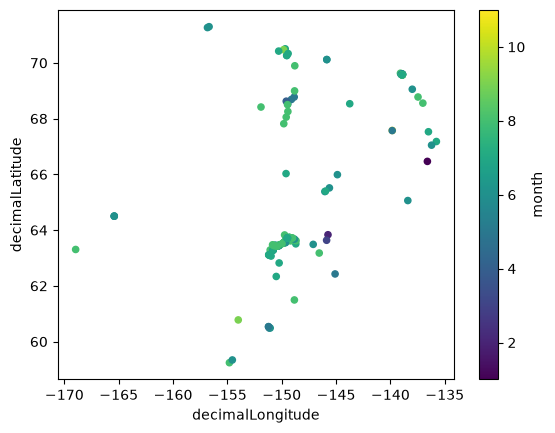

In [108]:
caribou_gbif_df.plot.scatter('decimalLongitude','decimalLatitude',c='month',cmap='viridis')

## Load ecoregions

In [74]:
### get url for ecoregions
ecoreg_url = ("https://storage.googleapis.com/"
       "teow2016/Ecoregions2017.zip")

### name the ecoregions directory name and file name
ecoreg_dir = os.path.join(data_dir, "ecoregions")

### make the ecoregions directory
os.makedirs(ecoreg_dir, exist_ok = True)

### join ecoregions shapefile path
ecoreg_path = os.path.join(ecoreg_dir, 'ecoregions.shp')

### download the data once
if not os.path.exists(ecoreg_path):

       ###open file at url
       ecoreg_gdf = gpd.read_file(ecoreg_url)

       ### save it to the filepath we've defined
       ecoreg_gdf.to_file(ecoreg_path)

### open up the ecoregions boundaries
ecoreg_gdf = gpd.read_file(ecoreg_path)
ecoreg_gdf


,OBJECTID,ECO_NAME,BIOME_NUM,BIOME_NAME,REALM,ECO_BIOME_,NNH,ECO_ID,SHAPE_LENG,SHAPE_AREA,NNH_NAME,COLOR,COLOR_BIO,COLOR_NNH,LICENSE,geometry
0,1.0,Adelie Land tundra,11.0,Tundra,Antarctica,AN11,1,117,9.749780,0.038948,Half Protected,#63CFAB,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((158.7141 -69.60657, 158.71264 ..."
1,2.0,Admiralty Islands lowland rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Australasia,AU01,2,135,4.800349,0.170599,Nature Could Reach Half Protected,#70A800,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((147.28819 -2.57589, 147.2715 -..."
2,3.0,Aegean and Western Turkey sclerophyllous and m...,12.0,"Mediterranean Forests, Woodlands & Scrub",Palearctic,PA12,4,785,162.523044,13.844952,Nature Imperiled,#FF7F7C,#FE0000,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((26.88659 35.32161, 26.88297 35..."
3,4.0,Afghan Mountains semi-desert,13.0,Deserts & Xeric Shrublands,Palearctic,PA13,4,807,15.084037,1.355536,Nature Imperiled,#FA774D,#CC6767,#EE1E23,CC-BY 4.0,"MULTIPOLYGON (((65.48655 34.71401, 65.52872 34..."
4,5.0,Ahklun and Kilbuck Upland Tundra,11.0,Tundra,Nearctic,NE11,1,404,22.590087,8.196573,Half Protected,#4C82B6,#9ED7C2,#257339,CC-BY 4.0,"MULTIPOLYGON (((-160.26404 58.64097, -160.2673..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
842,848.0,Sulawesi lowland rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Australasia,AU01,2,156,150.744361,9.422097,Nature Could Reach Half Protected,#70A800,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((117.33111 -7.53306, 117.30525 ..."
843,212.0,East African montane forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,AF01,3,8,157.848926,5.010930,Nature Could Recover,#13ED00,#38A700,#F9A91B,CC-BY 4.0,"MULTIPOLYGON (((36.7375 -3.13, 36.7375 -3.1316..."
844,224.0,Eastern Arc forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,AF01,3,9,34.153333,0.890325,Nature Could Recover,#267400,#38A700,#F9A91B,CC-BY 4.0,"MULTIPOLYGON (((36.38 -8.96583, 36.38 -8.96667..."
845,79.0,Borneo montane rain forests,1.0,Tropical & Subtropical Moist Broadleaf Forests,Indomalayan,IN01,2,220,38.280990,9.358407,Nature Could Reach Half Protected,#23DB01,#38A700,#7BC141,CC-BY 4.0,"MULTIPOLYGON (((112.82394 -0.5066, 112.82298 -..."


<Axes: >

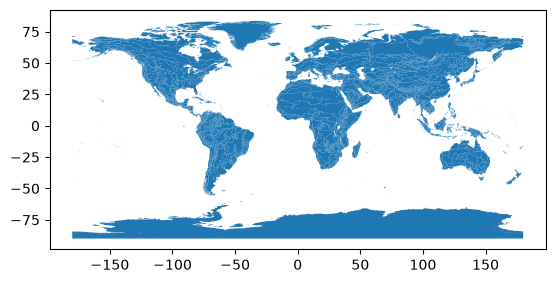

In [70]:
ecoreg_gdf.plot()

In [75]:
### simplify the geometry to speed up processing
ecoreg_gdf.geometry = ecoreg_gdf.simplify(tolerance = 0.05, preserve_topology = False)

### change the CRS to Mercator for mapping
ecoreg_gdf = ecoreg_gdf.to_crs(ccrs.Mercator())

### check that the plot runs in a reasonable amount of time
ecoreg_gdf.hvplot(geo = True, crs = ccrs.Mercator())

/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/pyth

:Polygons   [Longitude,Latitude]

## Connect the GBIF observations to ecoregions

In [77]:
### join gbif observations to ecoregions
gbif_ecoregion_gdf = (
    ecoreg_gdf

    ### match the CRS of gbif and ecoreg
    .to_crs(caribou_gbif_gdf.crs)

    ### find ecoregion for each observation
    .sjoin(
        caribou_gbif_gdf,

        ### type of database join
        how = 'inner',

        ### type of spatial join
        predicate = 'contains')

        ### rename columns
        [['OBJECTID','month','year']].rename(columns = {'OBJECTID':'ecoregion'}
    )
)

gbif_ecoregion_gdf

,ecoregion,month,year
9,10.0,9,2018
9,10.0,7,2025
9,10.0,8,2025
9,10.0,6,2024
9,10.0,8,2025
...,...,...,...
335,339.0,6,2013
335,339.0,7,2020
534,539.0,6,2024
534,539.0,1,2024


## Count average observations in each ecoregion each month and normalize

In [89]:
### summarize occurrences by ecoregion and month
caribou_occurrence_df = (
    gbif_ecoregion_gdf

    ### group by ecoregion and month
    .groupby(['ecoregion','month'])

    ### count the number of occurrences
    .agg(occurrence=('ecoregion','count'))
)


### calculate mean observations by ecoregion
mean_occurrence_ecoreg = (
    caribou_occurrence_df
    .groupby('ecoregion')
    .mean()
)

### calculate mean observations by month
mean_occurrence_month = (
    caribou_occurrence_df
    .groupby('month')
    .mean()
)

caribou_occurrence_df

occurrence
ecoregion month            
10.0      2               1
          3               1
          5               2
          6              13
          7              12
          8              38
          9               1
11.0      6               1
          8               1
41.0      6               3
          7               4
          9               1
43.0      6               4
          8               6
70.0      8               1
71.0      6               3
84.0      4               1
          5               3
          6               1
          7               2
          8               6
177.0     5               2
          6               2
          7               1
180.0     5               1
207.0     7               4
          8               1
337.0     5               1
          6               1
          7               1
          11              1
339.0     6               2
          7               1
539.0     1               1
          6               1
          7               1

In [90]:
### normalize by space and time
caribou_occurrence_df['norm_occurrences']=(
    caribou_occurrence_df
    / mean_occurrence_ecoreg
    / mean_occurrence_month
)

caribou_occurrence_df

occurrence  norm_occurrences
ecoregion month                              
10.0      2               1          0.102941
          3               1          0.102941
          5               2          0.114379
          6              13          0.431689
          7              12          0.380090
          8              38          0.442841
          9               1          0.102941
11.0      6               1          0.322581
          8               1          0.113208
41.0      6               3          0.362903
          7               4          0.461538
          9               1          0.375000
43.0      6               4          0.258065
          8               6          0.135849
70.0      8               1          0.113208
71.0      6               3          0.322581
84.0      4               1          0.384615
          5               3          0.641026
          6               1          0.124069
          7               2          0.236686
          8               6          0.261248
177.0     5               2          0.666667
          6               2          0.387097
          7               1          0.184615
180.0     5               1          0.555556
207.0     7               4          0.492308
          8               1          0.045283
337.0     5               1          0.555556
          6               1          0.322581
          7               1          0.307692
          11              1          1.000000
339.0     6               2          0.430108
          7               1          0.205128
539.0     1               1          1.000000
          6               1          0.322581
          7               1          0.307692

<Axes: xlabel='month', ylabel='norm_occurrences'>

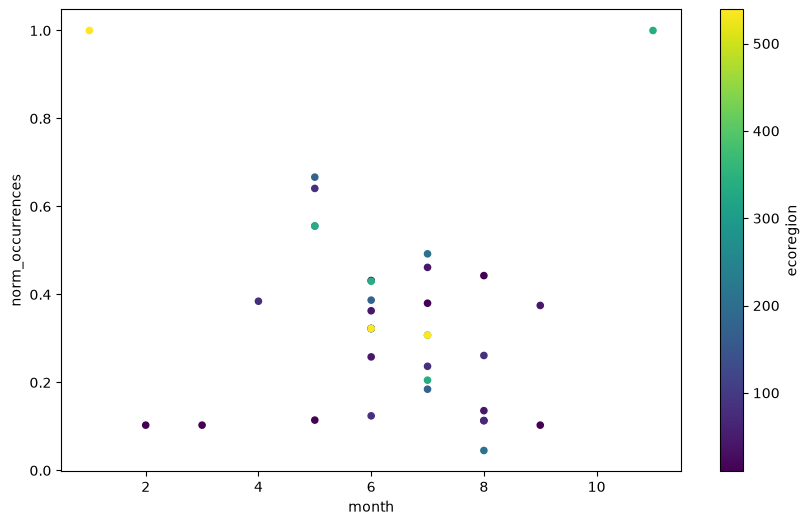

In [91]:
### create scatterplot of month and norm occurrences
caribou_occurrence_df.reset_index().plot.scatter(x='month',y='norm_occurrences',c='ecoregion',figsize=(10,6))

There are more observations of caribou in the summer months in many different ecoregions.

## Map caribou migration

In [92]:
### simplify the geometry to speed up processing
ecoreg_gdf.geometry = ecoreg_gdf.simplify(tolerance = 0.05, preserve_topology = False)

### change the CRS to Mercator for mapping
ecoreg_gdf = ecoreg_gdf.to_crs(ccrs.Mercator())

### check that the plot runs in a reasonable amount of time
ecoreg_gdf.hvplot(geo = True, crs = ccrs.Mercator())

/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/pyth

:Polygons   [Longitude,Latitude]

In [93]:
### prep the data, then combine the occurrence data with the ecoregions

### rename columns in ecoregID to match occurrence_df
ecoreg_gdf = ecoreg_gdf.rename(columns = {'OBJECTID': 'ecoregion'})

### make ecoreg ID the index for merge with occurrence_df
ecoreg_gdf = ecoreg_gdf.set_index('ecoregion')

### join the occurrences with the plotting GeoDataFrame
caribou_occurrence_df = ecoreg_gdf.join(caribou_occurrence_df)

caribou_occurrence_df.head()

ECO_NAME  BIOME_NUM BIOME_NAME  \
ecoregion month                                                        
10.0      2      Alaska-St. Elias Range tundra       11.0     Tundra   
          3      Alaska-St. Elias Range tundra       11.0     Tundra   
          5      Alaska-St. Elias Range tundra       11.0     Tundra   
          6      Alaska-St. Elias Range tundra       11.0     Tundra   
          7      Alaska-St. Elias Range tundra       11.0     Tundra   

                    REALM ECO_BIOME_  NNH  ECO_ID  SHAPE_LENG  SHAPE_AREA  \
ecoregion month                                                             
10.0      2      Nearctic       NE11    2     405   98.400727    28.38801   
          3      Nearctic       NE11    2     405   98.400727    28.38801   
          5      Nearctic       NE11    2     405   98.400727    28.38801   
          6      Nearctic       NE11    2     405   98.400727    28.38801   
          7      Nearctic       NE11    2     405   98.400727    28.38801   

                                          NNH_NAME    COLOR COLOR_BIO  \
ecoregion month                                                         
10.0      2      Nature Could Reach Half Protected  #61D2F2   #9ED7C2   
          3      Nature Could Reach Half Protected  #61D2F2   #9ED7C2   
          5      Nature Could Reach Half Protected  #61D2F2   #9ED7C2   
          6      Nature Could Reach Half Protected  #61D2F2   #9ED7C2   
          7      Nature Could Reach Half Protected  #61D2F2   #9ED7C2   

                COLOR_NNH    LICENSE  \
ecoregion month                        
10.0      2       #7BC141  CC-BY 4.0   
          3       #7BC141  CC-BY 4.0   
          5       #7BC141  CC-BY 4.0   
          6       #7BC141  CC-BY 4.0   
          7       #7BC141  CC-BY 4.0   

                                                          geometry  \
ecoregion month                                                      
10.0      2      MULTIPOLYGON (((-16886356.561 9047887.14, -168...   
          3      MULTIPOLYGON (((-16886356.561 9047887.14, -168...   
          5      MULTIPOLYGON (((-16886356.561 9047887.14, -168...   
          6      MULTIPOLYGON (((-16886356.561 9047887.14, -168...   
          7      MULTIPOLYGON (((-16886356.561 9047887.14, -168...   

                 occurrence  norm_occurrences  
ecoregion month                                
10.0      2               1          0.102941  
          3               1          0.102941  
          5               2          0.114379  
          6              13          0.431689  
          7              12          0.380090

In [94]:
### activate panel and hvplot extensions

pn.extension()
hv.extension("bokeh")

In [97]:
### get plot bounds
xmin, ymin,xmax,ymax=caribou_occurrence_df.total_bounds

### define slider widget
slider = pn.widgets.DiscreteSlider(
    name = 'month',
    options = {calendar.month_name[i]:i for i in range(1,13)}
)

### make basemap tile object
carto_tiles = hv.Tiles(
    ("https://basemaps.cartocdn.com/rastertiles/voyager/{Z}/{X}/{Y}.png"
     "?key=cb1_446c_1_8946b413de0ace50f732dbf1"),
     name="CARTO"
)

### plot the occurrence by month and ecoregion
migration_plot = (
    caribou_occurrence_df.hvplot(

        c = 'norm_occurrences',
        groupby = 'month',
        geo=True, crs=ccrs.Mercator(),

        ### fix colorbar range to be consistent across months
        clim = (0, 1),

        ### add the basemap
        tiles = carto_tiles,

        title = "Caribou Occurrences by Month",
        xlim = (xmin,xmax),ylim=(ymin,ymax),
        frame_height = 600, frame_width = 900,
        widget_location = 'bottom',

        colorbar = True,
        widgets = {'month':slider})
)

### wrap plot with panel
interactive_migration_plot = pn.panel(migration_plot)

interactive_migration_plot

/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/pyth

BokehModel(combine_events=True, render_bundle={'docs_json': {'2eff8368-dbf0-4f82-b043-22a3bd80a319': {'version…

In [96]:
### make path for map to live
data_dir = '/Users/sofieappel/Documents/GitHub/sofieappel.github.io/img'
map_path = os.path.join(data_dir, "caribou_migration.html")

### make a version for export, without the basemap
export_migration_plot = (
    caribou_occurrence_df.hvplot(
    
            c = 'norm_occurrences',
            group_by = 'month',
            geo=True, crs=ccrs.Mercator(),
    
            ### add the basemap
            tiles = carto_tiles,
    
            title = "Caribou Occurrences by Month",
            xlim = (xmin,xmax),ylim=(ymin,ymax),
            frame_height = 600, frame_width = 900,
            widget_location = 'bottom',
    
            colorbar = True,
            widgets = {'month':slider})
    )


### export the map as an .html file
export_migration_plot.save(
    map_path,
    embed = True,
    resources = "inline",
)

/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/miniconda3/envs/earth-analytics-python/lib/pyth

## Store variables for additional notebook

In [109]:
%store ecoreg_gdf

Stored 'ecoreg_gdf' (GeoDataFrame)
